# Logistic Regression

## Load Data

In [1]:
import sys
from pathlib import Path

# Find project root automatically
project_root = Path.cwd()

# Keep going up the directory tree until we find a directory that contains a "src" folder
while not (project_root / "src").is_dir():
    if project_root == project_root.parent:
        raise FileNotFoundError("Could not locate project root")
    project_root = project_root.parent
# Add the project root to the system path so we can import modules from src
sys.path.insert(0, str(project_root))

from src.data.load_data import load_nsl_kdd

# Load the NSL-KDD dataset
train_df, test_df = load_nsl_kdd()
train_df.head()

True


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class,y
0,0.0,tcp,ftp_data,SF,491.0,0.0,0,0.0,0.0,0.0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,0
1,0.0,udp,other,SF,146.0,0.0,0,0.0,0.0,0.0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,0
2,0.0,tcp,private,S0,0.0,0.0,0,0.0,0.0,0.0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly,1
3,0.0,tcp,http,SF,232.0,8153.0,0,0.0,0.0,0.0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,0
4,0.0,tcp,http,SF,199.0,420.0,0,0.0,0.0,0.0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,0


## Preprocessing

In [2]:
from src.data.preprocess import prep

# Preprocess the training data
target = train_df["y"]
preprocessor = prep()
train_df_preprocessed = preprocessor.fit_transform(train_df)

#print(target)
print(train_df_preprocessed)

[[-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 ...
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]]


## Train Model

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(train_df_preprocessed, target, test_size=0.2, random_state=42, stratify=target)

# Initialize the logistic regression model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## Make Predictions

In [ ]:
# Make predictions on the test set
predictions = model.predict(X_test)
print(predictions)

# Probabilities of the predictions
probabilities = model.predict_proba(X_test)
print(probabilities)

[1 0 1 ... 0 1 1]
[[0.00149282 0.99850718]
 [0.99039984 0.00960016]
 [0.00119676 0.99880324]
 ...
 [0.64964578 0.35035422]
 [0.03009061 0.96990939]
 [0.30124569 0.69875431]]


## Display Results

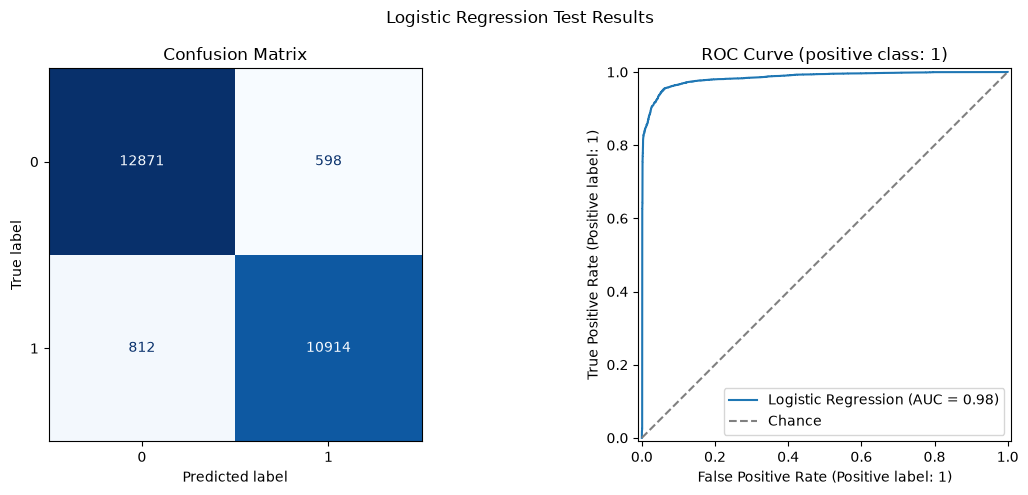

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

positive_class = model.classes_[1]
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    ax=axs[0],
    cmap="Blues",
    colorbar=False,
)
axs[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test,
    probabilities[:, 1],
    pos_label=positive_class,
    name="Logistic Regression",
    ax=axs[1],
)
axs[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axs[1].set_title(f"ROC Curve (positive class: {positive_class})")
axs[1].legend()

fig.suptitle("Logistic Regression Test Results")
fig.tight_layout()
plt.show()